<a href="https://colab.research.google.com/github/jorge-rodriguez-ramos/afm_jrr/blob/main/notebooks/example_afm_dl_jrr.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Atomic Force Microscopy (AFM) Force Curves Classification Demo

> SPDX-FileCopyrightText: 2026 Jorge Rodriguez Ramos
>
> SPDX-License-Identifier: GPL-3.0-or-later
>
> This file is part of `afm_jrr`.
>
> `afm_jrr` is free software: you can redistribute it and/or modify it under
> the terms of the GNU General Public License as published by the Free Software
> Foundation, either version 3 of the License, or (at your option) any later
> version.
>
> `afm_jrr` is distributed in the hope that it will be useful, but WITHOUT ANY
> WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR
> A PARTICULAR PURPOSE. See the GNU General Public License for more details.
>
> You should have received a copy of the GNU General Public License along with
> `afm_jrr`. If not, see [https://www.gnu.org/licenses/](https://www.gnu.org/licenses/).

### 📋 Key Steps Included:
1. **Environment Setup:** Verifies GPU availability (minimum: T4 GPU) and installs the custom module `afm_dl_jrr` directly from the `afm_jrr` GitHub repository.
2. **Dataset Acquisition:** Automatically pulls and extracts the zipped dataset hosted on **Zenodo** (no Google Drive access required).
3. **Data Splitting:** Splits the raw data into stratified training and testing subsets.
4. **Model Training:** Trains the ResNet-18 network over 100 epochs, focusing on maximizing classification metrics (like the F1-Score).
5. **Evaluation:** Loads the optimal model weights, runs predictions on the test set, and outputs a complete confusion matrix and classification report against the Ground Truth.

# Prepare the system to use the the module `afm_dl_jrr`

In [1]:
# @title Check that GPU is available
# @markdown > *Use at least T4 runtime*
import torch
import os
import sys
import time

gpu = torch.cuda.is_available()

if not gpu:
    print("Warning: GPU not detected. Stopping kernel.")
    print("To use a GPU, go to the menu: 'Runtime' -> 'Change runtime type' and select 'T4 GPU' from the Hardware accelerator dropdown.")

    # Ensure the output is flushed to the frontend
    sys.stdout.flush()
    # Brief sleep to allow the message to be transmitted before the process dies
    time.sleep(1)

    # Terminate the kernel process
    os.kill(os.getpid(), 9)

else:
    print(f"GPU detected: {torch.cuda.get_device_name(0)}")

GPU detected: NVIDIA RTX PRO 6000 Blackwell Server Edition


In [2]:
# @title Import `jrr_afm` repo

owner = "jorge-rodriguez-ramos"
repo = "afm_jrr"

!pip install git+https://github.com/{owner}/{repo}.git -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 181.5/181.5 kB 9.5 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


# Prepare the dataset

In [ ]:
# @title Import the dataset from Zenodo
# @markdown Ref: https://doi.org/10.5281/zenodo.23360912

from afm_dl_jrr.aux import extract_and_organize_zip

!wget -c "https://zenodo.org/records/23360912/files/GT_pathway2_raw.zip?download=1" -O dataset.zip

extract_and_organize_zip('/content/dataset.zip', '/content/data')


In [4]:
# @title Split the data in train and test subsets
from afm_dl_jrr.build_gt import split_gt_for_training

summary = split_gt_for_training(
    '/content/data/',
    good_test_ratio=0.10,
    bad_test_ratio=0.70,
    seed=42
)
print("Dataset summary:", 16*"=", sep="\n")
for key, value in summary.items():
    print(f"{key}: {value}")

Dataset summary:
good_total: 128
bad_total: 1367
train_good: 115
train_bad: 410
test_good: 13
test_bad: 957


# Train

In [ ]:
# @title Train the model
EPOCHS = 100 # @param {"type":"integer","placeholder":"100"}

import os
import time
from afm_dl_jrr.resnet import set_seed, build_loaders, build_model, train, run_visualization, predict_curve
DATA_DIR = '/content/data/train_dataset'
SEED = 42
set_seed(SEED, deterministic=True)

train_loader, val_loader, full_dataset = build_loaders(DATA_DIR)
model, optimizer, criterion = build_model()

start_time = time.perf_counter()
train(
    model,
    optimizer,
    criterion,
    train_loader,
    val_loader,
    full_dataset.classes,
    epochs=EPOCHS,
    selection_metric='f1' # default:recall, other: f1
)
elapsed_seconds = time.perf_counter() - start_time

print(f"Training complete in {elapsed_seconds:.2f} seconds ({elapsed_seconds / 60:.2f} minutes).")

# Test

In [9]:
# @title Load the model

import torch
from afm_dl_jrr.resnet import build_model

MODEL = '/content/resnet18_bw_best.pth'

# Create an instance of your model architecture
model, optimizer, criterion = build_model()
# Load the saved weights
model.load_state_dict(torch.load(MODEL))

# Set to evaluation mode if you're doing inference
model.eval()
print('✅ Model loaded')

✅ Model loaded


In [ ]:
# @title Make predictions
from afm_dl_jrr.aux import make_predictions_folder

WORK_DIR = '/content/data/test_dataset'

# --- Execution ---
# @markdown Adjust the thresholds
threshold_low = 0.5 #@param {type:"slider", min:0, max:1, step:0.01}
threshold_high = 0.8 #@param {type:"slider", min:0, max:1, step:0.01}

# Run the function
df_predictions, n_good, n_bad, n_verify = make_predictions_folder(
    model=model,
    work_dir=WORK_DIR,
    threshold_low=threshold_low,
    threshold_high=threshold_high
)

# Save and Display
folder_name = os.path.basename(WORK_DIR).split('.')[0]
output_csv_path = f'predictions.csv'
df_predictions.to_csv(output_csv_path, index=False)

print(f"\nPrediction results saved to {output_csv_path}")
display(df_predictions.head())

Total files evaluated: 970
Accuracy: 0.9237

Confusion matrix (rows=true, cols=pred):
      GOOD  BAD
GOOD    12    1
BAD     73  884

Classification report:
              precision    recall  f1-score   support

        GOOD       0.14      0.92      0.24        13
         BAD       1.00      0.92      0.96       957

    accuracy                           0.92       970
   macro avg       0.57      0.92      0.60       970
weighted avg       0.99      0.92      0.95       970

OVERALL:
  Total: 970, Correct: 896, Accuracy: 0.9237
  Clopper-Pearson 95% CI: [0.9062, 0.9402]

GOOD FILES:
  Total: 13, Correct: 12, TPR (Recall): 0.9231
  Clopper-Pearson 95% CI: [0.7692, 1.0000]

BAD FILES:
  Total: 957, Correct: 884, TNR (Specificity): 0.9237
  Clopper-Pearson 95% CI: [0.9070, 0.9404]


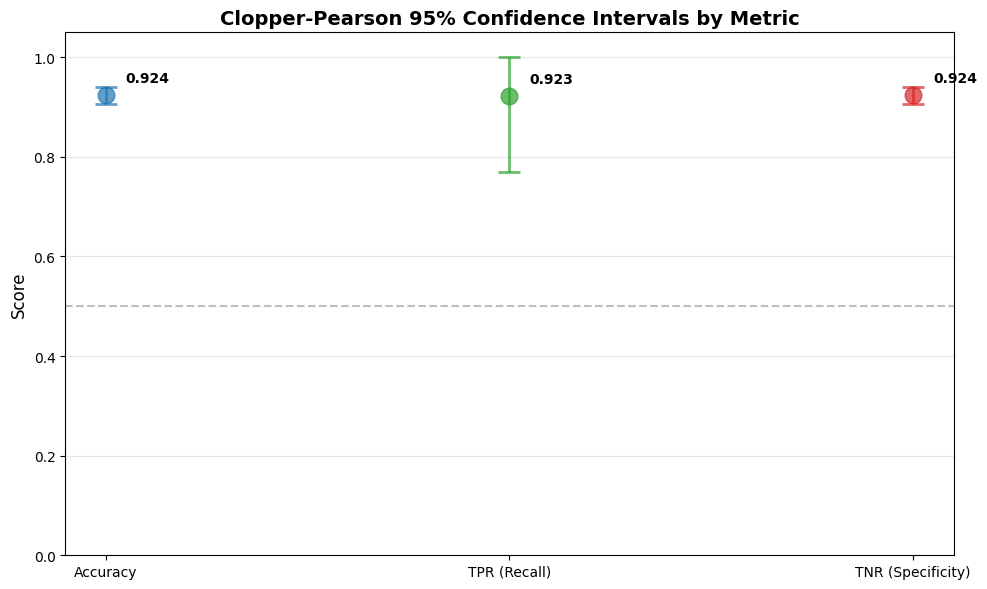

In [11]:
# @title Prediction stats if ground truth file is provided
GT_path = "/content/data/good_files.csv"

import os
from afm_dl_jrr.aux import evaluate_predictions

if not os.path.exists(GT_path):
    raise ValueError(f"File not found: {GT_path}")

# read good files from GT_path
with open(GT_path, 'r') as f:
    good_files = f.read().splitlines()

# Call the evaluation function
pred_eval = evaluate_predictions(df_predictions, good_files)